# Sleep Staging — 03: Feature Engineering

**Objetivo:** transformar los epochs preprocesados en un dataset tabular de features clásicas para construir un baseline de machine learning interpretable.

**Entrada:** archivos preprocesados por sujeto `SN*.npz`.

**Salidas principales:**
- `../data/processed/features_full.parquet`
- `../data/processed/features_full.npz`
- `../data/processed/feature_catalog.csv`
- figuras en `../reports/figures/`

La notebook es reiniciable: si el Parquet final ya existe, se carga directamente y no se vuelven a abrir las señales completas. Si no existe, las features se extraen en chunks recuperables.


---
## 0. Setup

El backend gráfico se configura antes de importar `pyplot` para evitar problemas con el kernel de VS Code.


In [1]:
from pathlib import Path
import gc
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from scipy.integrate import trapezoid
from scipy.signal import welch
from scipy.stats import skew, kurtosis

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

SUBJECT_DATA_DIR = Path(
    r"C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed"
)

OUTPUT_DIR = Path("../data/processed")
CHUNKS_DIR = OUTPUT_DIR / "feature_chunks"
FIGURES_DIR = Path("../reports/figures")

FINAL_PARQUET = OUTPUT_DIR / "features_full.parquet"
FINAL_NPZ = OUTPUT_DIR / "features_full.npz"
CATALOG_PATH = OUTPUT_DIR / "feature_catalog.csv"

for directory in (OUTPUT_DIR, CHUNKS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

EXPECTED_SFREQ = 100
EPOCH_DURATION = 30
CHUNK_SIZE = 5000
EPS = 1e-12
RANDOM_STATE = 42
HIGH_CORR_THRESHOLD = 0.95
MAX_SAMPLES_PER_STAGE = 3000

FREQ_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "sigma": (12.0, 15.0),
    "beta": (15.0, 30.0),
}

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_COLORS = {
    "W": "#e74c3c",
    "N1": "#f39c12",
    "N2": "#3498db",
    "N3": "#2c3e50",
    "REM": "#27ae60",
}

print("Setup completado.")
print("Entrada:", SUBJECT_DATA_DIR)
print("Salida:", OUTPUT_DIR.resolve())


Setup completado.
Entrada: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed
Salida: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed


---
## 1. Carga eficiente

Primero se comprueba si el dataset tabular final ya existe. Si existe, se evita cargar `X`, que puede ocupar varios GB.


In [2]:
def decode_text(value):
    """Convierte bytes y escalares NumPy a texto."""
    return value.decode("utf-8") if isinstance(value, bytes) else str(value)


def find_key(dataset, candidates, description, required=True):
    """Busca la primera key disponible."""
    key = next((name for name in candidates if name in dataset.files), None)

    if required and key is None:
        raise KeyError(
            f"No se encontró '{description}'. "
            f"Disponibles: {dataset.files}; esperadas: {candidates}"
        )

    return key


def infer_channels_from_features(columns):
    """Recupera nombres de canales desde columnas canal__feature."""
    return sorted({col.split("__", 1)[0] for col in columns if "__" in col})


In [3]:
if FINAL_PARQUET.exists():
    print("Se encontró el dataset final. Se omite la carga de señales.")
    features_df = pd.read_parquet(FINAL_PARQUET)

    METADATA_COLS = ["epoch_global", "epoch_in_subject", "label", "subject"]
    FEATURE_COLS = [col for col in features_df.columns if col not in METADATA_COLS]

    y = features_df["label"].to_numpy(dtype=np.int8)
    subjects = features_df["subject"].astype(str).to_numpy()
    CH_NAMES = infer_channels_from_features(FEATURE_COLS)

    n_epochs = len(features_df)
    n_channels = len(CH_NAMES)
    SFREQ = EXPECTED_SFREQ
    X = None
    NEED_EXTRACTION = False

    print(f"Shape cargado: {features_df.shape}")
    print(f"Features: {len(FEATURE_COLS)}")
else:
    NEED_EXTRACTION = True
    print("No existe el dataset final. Será necesario extraer features.")


Se encontró el dataset final. Se omite la carga de señales.
Shape cargado: (127904, 197)
Features: 193


### 1.1 Carga de señales solo cuando es necesaria


In [4]:
if NEED_EXTRACTION:
    if not SUBJECT_DATA_DIR.exists():
        raise FileNotFoundError(
            f"No se encontró la carpeta de entrada:\n{SUBJECT_DATA_DIR}"
        )

    subject_files = sorted(SUBJECT_DATA_DIR.glob("SN*.npz"))

    if not subject_files:
        raise FileNotFoundError(
            f"No se encontraron archivos SN*.npz en:\n{SUBJECT_DATA_DIR}"
        )

    with np.load(subject_files[0], allow_pickle=True) as first:
        X_KEY = find_key(
            first,
            ["X", "epochs", "signals", "data", "X_processed"],
            "señales",
        )
        Y_KEY = find_key(
            first,
            ["y", "labels", "stages", "sleep_stages"],
            "labels",
        )
        CHANNELS_KEY = find_key(
            first,
            ["channel_names", "ch_names", "channels"],
            "nombres de canales",
            required=False,
        )
        SFREQ_KEY = find_key(
            first,
            ["sfreq", "sampling_rate", "fs"],
            "frecuencia de muestreo",
            required=False,
        )

        first_channels = (
            [decode_text(ch) for ch in first[CHANNELS_KEY]]
            if CHANNELS_KEY
            else None
        )
        first_sfreq = (
            float(np.asarray(first[SFREQ_KEY]).squeeze())
            if SFREQ_KEY
            else EXPECTED_SFREQ
        )

    X_parts, y_parts, subject_parts = [], [], []
    reference_shape = None

    for path in subject_files:
        subject_id = path.stem

        with np.load(path, allow_pickle=True) as data:
            X_subject = data[X_KEY]
            y_subject = data[Y_KEY].astype(np.int8)

        if X_subject.ndim != 3:
            raise ValueError(f"{subject_id}: shape inválido {X_subject.shape}")

        if len(X_subject) != len(y_subject):
            raise ValueError(f"{subject_id}: X e y no están alineados")

        if reference_shape is None:
            reference_shape = X_subject.shape[1:]
        elif X_subject.shape[1:] != reference_shape:
            raise ValueError(
                f"{subject_id}: se esperaba {reference_shape}, "
                f"pero se encontró {X_subject.shape[1:]}"
            )

        X_parts.append(X_subject)
        y_parts.append(y_subject)
        subject_parts.append(
            np.full(len(y_subject), subject_id, dtype=object)
        )

    X = np.concatenate(X_parts)
    y = np.concatenate(y_parts)
    subjects = np.concatenate(subject_parts).astype(str)

    del X_parts, y_parts, subject_parts
    gc.collect()

    n_epochs, n_channels, n_samples = X.shape
    CH_NAMES = first_channels or [f"channel_{i}" for i in range(n_channels)]
    SFREQ = first_sfreq

    assert len(y) == len(subjects) == n_epochs
    assert len(CH_NAMES) == n_channels
    assert np.isfinite(X).all()
    assert set(np.unique(y)).issubset(STAGE_MAP)

    print(f"Archivos:      {len(subject_files)}")
    print(f"X:             {X.shape}")
    print(f"Memoria de X:  {X.nbytes / 1024**3:.2f} GB")
    print(f"SFREQ:         {SFREQ:g} Hz")
    print(f"Canales:       {CH_NAMES}")
    print(f"Sujetos:       {len(np.unique(subjects))}")


---
## 2. Canales y estrategia de features


In [5]:
def infer_channel_type(channel_name):
    """Clasifica un canal por su nombre."""
    name = channel_name.upper()

    if "EEG" in name:
        return "EEG"
    if "EOG" in name:
        return "EOG"
    if "EMG" in name:
        return "EMG"
    return "OTHER"


channel_catalog = pd.DataFrame({
    "channel": CH_NAMES,
    "channel_type": [infer_channel_type(ch) for ch in CH_NAMES],
})

display(channel_catalog)


,channel,channel_type
0,EEG C3-M2,EEG
1,EEG C4-M1,EEG
2,EEG F4-M1,EEG
3,EEG O2-M1,EEG
4,EMG chin,EMG
5,EOG E1-M2,EOG
6,EOG E2-M2,EOG


---
## 3. Funciones de extracción


In [6]:
def safe_float(value, default=0.0):
    """Convierte a float y reemplaza valores no finitos para robustecer la extracción."""
    value = float(value)
    return value if np.isfinite(value) else float(default)


def temporal_features(sig):
    """Features de dominio temporal para un canal de un epoch."""
    zero_crossings = np.mean(np.signbit(sig[:-1]) != np.signbit(sig[1:]))
    return {
        "mean": safe_float(np.mean(sig)),
        "std": safe_float(np.std(sig)),
        "var": safe_float(np.var(sig)),
        "rms": safe_float(np.sqrt(np.mean(sig ** 2))),
        "ptp": safe_float(np.ptp(sig)),
        "skew": safe_float(skew(sig, bias=False)),
        "kurt": safe_float(kurtosis(sig, fisher=True, bias=False)),
        "zcr": safe_float(zero_crossings),
    }


def hjorth_features(sig):
    """Parámetros de Hjorth: activity, mobility y complexity."""
    d1 = np.diff(sig)
    d2 = np.diff(d1)

    activity = np.var(sig)
    mobility = np.sqrt((np.var(d1) + EPS) / (activity + EPS))
    complexity = np.sqrt((np.var(d2) + EPS) / (np.var(d1) + EPS)) / (mobility + EPS)

    return {
        "hjorth_activity": safe_float(activity),
        "hjorth_mobility": safe_float(mobility),
        "hjorth_complexity": safe_float(complexity),
    }


def permutation_entropy(sig, order=3, delay=1, normalize=True):
    """
    Entropía de permutación de Bandt-Pompe.
    Mide cuán impredecible es el orden local de los valores de una señal.
    """
    n_vectors = len(sig) - delay * (order - 1)
    if n_vectors <= 0:
        return 0.0

    patterns = np.empty((n_vectors, order), dtype=int)
    for j in range(order):
        patterns[:, j] = np.arange(j * delay, j * delay + n_vectors)

    ordinal_patterns = np.argsort(sig[patterns], axis=1, kind="mergesort")
    _, counts = np.unique(ordinal_patterns, axis=0, return_counts=True)
    probabilities = counts / counts.sum()

    entropy_value = -np.sum(probabilities * np.log2(probabilities + EPS))
    if normalize:
        entropy_value /= np.log2(math.factorial(order))
    return safe_float(entropy_value)


def complexity_features(sig):
    """Resumen no lineal compacto."""
    return {"perm_entropy": permutation_entropy(sig, order=3, normalize=True)}


In [7]:
def _welch_psd(sig, sfreq, nperseg=None):
    """PSD de Welch con segmentos de aproximadamente 4 segundos y 50% de overlap."""
    if nperseg is None:
        nperseg = min(len(sig), int(round(4 * sfreq)))
    noverlap = nperseg // 2
    freqs, psd = welch(sig, fs=sfreq, nperseg=nperseg, noverlap=noverlap)
    return freqs, psd


def _band_power(freqs, psd, low, high):
    """Integra la PSD en una banda de frecuencia."""
    mask = (freqs >= low) & (freqs < high)
    if mask.sum() < 2:
        return 0.0
    return safe_float(trapezoid(psd[mask], freqs[mask]))


def _spectral_summary(freqs, psd, low=0.5, high=35.0):
    """Entropía espectral y SEF95 dentro de una banda de interés."""
    mask = (freqs >= low) & (freqs <= high)
    band_freqs = freqs[mask]
    band_psd = psd[mask]

    if len(band_freqs) < 2 or np.sum(band_psd) <= EPS:
        return {"spectral_entropy": 0.0, "sef95": 0.0}

    probabilities = band_psd / np.sum(band_psd)
    spectral_entropy = -np.sum(probabilities * np.log2(probabilities + EPS))
    spectral_entropy /= np.log2(len(probabilities))

    cumulative_power = np.cumsum(band_psd)
    cutoff_idx = np.searchsorted(cumulative_power, 0.95 * cumulative_power[-1])
    cutoff_idx = min(cutoff_idx, len(band_freqs) - 1)

    return {
        "spectral_entropy": safe_float(spectral_entropy),
        "sef95": safe_float(band_freqs[cutoff_idx]),
    }


def eeg_eog_spectral_features(sig, sfreq):
    """Features espectrales completas para EEG y EOG."""
    freqs, psd = _welch_psd(sig, sfreq)
    total_power = _band_power(freqs, psd, *SIGNAL_BAND) + EPS

    features = {"total_power_0_5_35": safe_float(total_power)}
    band_powers = {}

    for band_name, (low, high) in FREQ_BANDS.items():
        power = _band_power(freqs, psd, low, high)
        band_powers[band_name] = power
        features[f"{band_name}_abs"] = power
        features[f"{band_name}_rel"] = safe_float(power / total_power)

    features.update(_spectral_summary(freqs, psd, *SIGNAL_BAND))

    features.update({
        "ratio_delta_beta": safe_float(band_powers["delta"] / (band_powers["beta"] + EPS)),
        "ratio_theta_alpha": safe_float(band_powers["theta"] / (band_powers["alpha"] + EPS)),
        "ratio_delta_theta": safe_float(band_powers["delta"] / (band_powers["theta"] + EPS)),
        "ratio_sigma_beta": safe_float(band_powers["sigma"] / (band_powers["beta"] + EPS)),
    })
    return features


def emg_spectral_features(sig, sfreq):
    """
    Resumen espectral acotado para EMG.
    El preprocessing limita la señal a 35 Hz, por lo que no pretendemos
    caracterizar el espectro EMG completo.
    """
    freqs, psd = _welch_psd(sig, sfreq)
    total_power = _band_power(freqs, psd, *SIGNAL_BAND) + EPS
    power_10_35 = _band_power(freqs, psd, 10.0, 35.0)
    power_20_35 = _band_power(freqs, psd, 20.0, 35.0)

    features = {
        "total_power_0_5_35": safe_float(total_power),
        "power_10_35": power_10_35,
        "power_20_35": power_20_35,
        "power_10_35_rel": safe_float(power_10_35 / total_power),
        "power_20_35_rel": safe_float(power_20_35 / total_power),
    }
    features.update(_spectral_summary(freqs, psd, *SIGNAL_BAND))
    return features


def generic_spectral_features(sig, sfreq):
    """Fallback para canales cuyo nombre no permite inferir el tipo."""
    freqs, psd = _welch_psd(sig, sfreq)
    total_power = _band_power(freqs, psd, *SIGNAL_BAND)
    features = {"total_power_0_5_35": total_power}
    features.update(_spectral_summary(freqs, psd, *SIGNAL_BAND))
    return features


In [8]:
def extract_epoch_features(epoch, channel_names, sfreq):
    """Extrae todas las features de un epoch."""
    row = {}

    for channel_idx, channel_name in enumerate(channel_names):
        signal = epoch[channel_idx].astype(np.float64, copy=False)
        channel_type = infer_channel_type(channel_name)
        prefix = f"{channel_name}__"

        groups = [
            temporal_features(signal),
            hjorth_features(signal),
            complexity_features(signal),
        ]

        if channel_type in {"EEG", "EOG"}:
            groups.append(eeg_eog_spectral_features(signal, sfreq))
        elif channel_type == "EMG":
            groups.append(emg_spectral_features(signal, sfreq))
        else:
            groups.append(generic_spectral_features(signal, sfreq))

        for group in groups:
            row.update({prefix + name: value for name, value in group.items()})

    return row


---
## 4. Extracción recuperable por chunks


In [9]:
def expected_chunk_paths(n_rows, chunk_size=CHUNK_SIZE):
    """Devuelve las rutas exactas de todos los chunks esperados."""
    return [
        CHUNKS_DIR
        / f"features_{start:06d}_{min(start + chunk_size, n_rows):06d}.parquet"
        for start in range(0, n_rows, chunk_size)
    ]


def extract_missing_chunks():
    """Extrae y guarda únicamente los chunks faltantes."""
    paths = expected_chunk_paths(n_epochs)
    missing = [path for path in paths if not path.exists()]

    if not missing:
        print(f"Todos los chunks ya existen ({len(paths)}).")
        return paths

    if X is None:
        raise RuntimeError("Faltan chunks, pero X no está cargado.")

    print(f"Chunks faltantes: {len(missing)} de {len(paths)}")

    for start in range(0, n_epochs, CHUNK_SIZE):
        end = min(start + CHUNK_SIZE, n_epochs)
        path = CHUNKS_DIR / f"features_{start:06d}_{end:06d}.parquet"

        if path.exists():
            continue

        rows = [
            extract_epoch_features(X[idx], CH_NAMES, SFREQ)
            for idx in range(start, end)
        ]

        chunk_df = pd.DataFrame.from_records(rows)
        indices = np.arange(start, end)

        chunk_df.insert(0, "epoch_global", indices.astype(np.int32))
        chunk_df["label"] = y[indices].astype(np.int8)
        chunk_df["subject"] = subjects[indices]

        feature_cols = [
            col
            for col in chunk_df.columns
            if col not in {"epoch_global", "label", "subject"}
        ]

        chunk_df[feature_cols] = (
            chunk_df[feature_cols]
            .replace([np.inf, -np.inf], np.nan)
            .astype(np.float32)
        )

        chunk_df.to_parquet(path, index=False, compression="snappy")

        del rows, chunk_df
        gc.collect()

        print(f"{end:>6}/{n_epochs} epochs | guardado: {path.name}")

    return paths


chunk_paths = (
    extract_missing_chunks()
    if NEED_EXTRACTION
    else expected_chunk_paths(n_epochs)
)


---
## 5. Construcción y control de calidad


In [10]:
if NEED_EXTRACTION:
    missing = [path for path in chunk_paths if not path.exists()]

    if missing:
        raise RuntimeError(f"Faltan {len(missing)} chunks.")

    features_df = pd.concat(
        [pd.read_parquet(path) for path in chunk_paths],
        ignore_index=True,
    )

    features_df = (
        features_df
        .sort_values("epoch_global")
        .reset_index(drop=True)
    )

    features_df["epoch_in_subject"] = (
        features_df.groupby("subject", sort=False).cumcount().astype(np.int32)
    )
    features_df["epoch_global"] = features_df["epoch_global"].astype(np.int32)
    features_df["label"] = features_df["label"].astype(np.int8)
    features_df["subject"] = features_df["subject"].astype("category")

    METADATA_COLS = ["epoch_global", "epoch_in_subject", "label", "subject"]
    FEATURE_COLS = [col for col in features_df.columns if col not in METADATA_COLS]
    features_df = features_df[METADATA_COLS + FEATURE_COLS]

print(f"Shape:      {features_df.shape}")
print(f"Features:   {len(FEATURE_COLS)}")
print(f"Memoria:    {features_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Shape:      (127904, 197)
Features:   193
Memoria:    100.2 MB


In [11]:
features_df[FEATURE_COLS] = (
    features_df[FEATURE_COLS]
    .replace([np.inf, -np.inf], np.nan)
)

missing_by_feature = features_df[FEATURE_COLS].isna().sum()
n_missing = int(missing_by_feature.sum())

print(f"Valores faltantes o no finitos: {n_missing}")

if n_missing:
    display(
        missing_by_feature[missing_by_feature > 0]
        .sort_values(ascending=False)
        .head(20)
        .rename("n_missing")
    )
    features_df[FEATURE_COLS] = features_df[FEATURE_COLS].fillna(0.0)
    print("Los valores faltantes se imputaron con 0.")

assert len(features_df) == len(y) == len(subjects)
assert np.isfinite(features_df[FEATURE_COLS].to_numpy()).all()

feature_variance = features_df[FEATURE_COLS].var()
constant_features = feature_variance[
    feature_variance <= 1e-12
].index.tolist()

print(f"Features constantes o casi constantes: {len(constant_features)}")


Valores faltantes o no finitos: 0
Features constantes o casi constantes: 0


### Liberación de señales


In [12]:
if X is not None:
    print(f"Liberando X ({X.nbytes / 1024**3:.2f} GB)...")
    del X
    X = None
    gc.collect()

print("Memoria de señales liberada.")


Memoria de señales liberada.


---
## 6. EDA breve


In [13]:
def first_channel_of_type(channel_type):
    return next(
        (
            channel
            for channel in CH_NAMES
            if infer_channel_type(channel) == channel_type
        ),
        None,
    )


main_eeg = first_channel_of_type("EEG")
main_eog = first_channel_of_type("EOG")
main_emg = first_channel_of_type("EMG")

candidate_features = []

if main_eeg:
    candidate_features += [
        (f"{main_eeg}__delta_rel", f"Delta relativa\n{main_eeg}"),
        (f"{main_eeg}__sigma_rel", f"Sigma relativa\n{main_eeg}"),
        (f"{main_eeg}__sef95", f"SEF95\n{main_eeg}"),
        (f"{main_eeg}__perm_entropy", f"Entropía de permutación\n{main_eeg}"),
    ]

if main_eog:
    candidate_features.append(
        (f"{main_eog}__ptp", f"Peak-to-peak\n{main_eog}")
    )

if main_emg:
    candidate_features.append(
        (f"{main_emg}__rms", f"RMS\n{main_emg}")
    )

candidate_features = [
    item for item in candidate_features if item[0] in features_df.columns
]

print("Candidate features:")
for column, _ in candidate_features:
    print(" -", column)


Candidate features:
 - EEG C3-M2__delta_rel
 - EEG C3-M2__sigma_rel
 - EEG C3-M2__sef95
 - EEG C3-M2__perm_entropy
 - EOG E1-M2__ptp
 - EMG chin__rms


In [24]:
BOXPLOT_PATH = FIGURES_DIR / "candidate_features_boxplot.png"

if not candidate_features:
    print("No se encontraron features candidatas para el boxplot.")
else:
    stage_ids = sorted(features_df["label"].unique())
    fig, axes = plt.subplots(
        1,
        len(candidate_features),
        figsize=(3.1 * len(candidate_features), 4.4),
        squeeze=False,
    )

    for ax, (feature_col, title) in zip(axes.ravel(), candidate_features):
        values_by_stage = []

        for stage_id in stage_ids:
            values = (
                features_df.loc[
                    features_df["label"] == stage_id,
                    feature_col,
                ]
                .replace([np.inf, -np.inf], np.nan)
                .dropna()
            )

            if len(values) > MAX_SAMPLES_PER_STAGE:
                values = values.sample(
                    MAX_SAMPLES_PER_STAGE,
                    random_state=RANDOM_STATE,
                )

            values_by_stage.append(values.to_numpy(dtype=np.float32))

        boxplot = ax.boxplot(
            values_by_stage,
            tick_labels=[STAGE_MAP[idx] for idx in stage_ids],
            patch_artist=True,
            showfliers=False,
            widths=0.65,
        )

        for patch, stage_id in zip(boxplot["boxes"], stage_ids):
            patch.set_facecolor(STAGE_COLORS[STAGE_MAP[stage_id]])
            patch.set_alpha(0.8)

        ax.set_title(title, fontsize=9)
        ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    fig.savefig(BOXPLOT_PATH, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print("Boxplot guardado:", BOXPLOT_PATH.resolve())


Boxplot guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\figures\candidate_features_boxplot.png


Boxplot guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\figures\candidate_features_boxplot.png


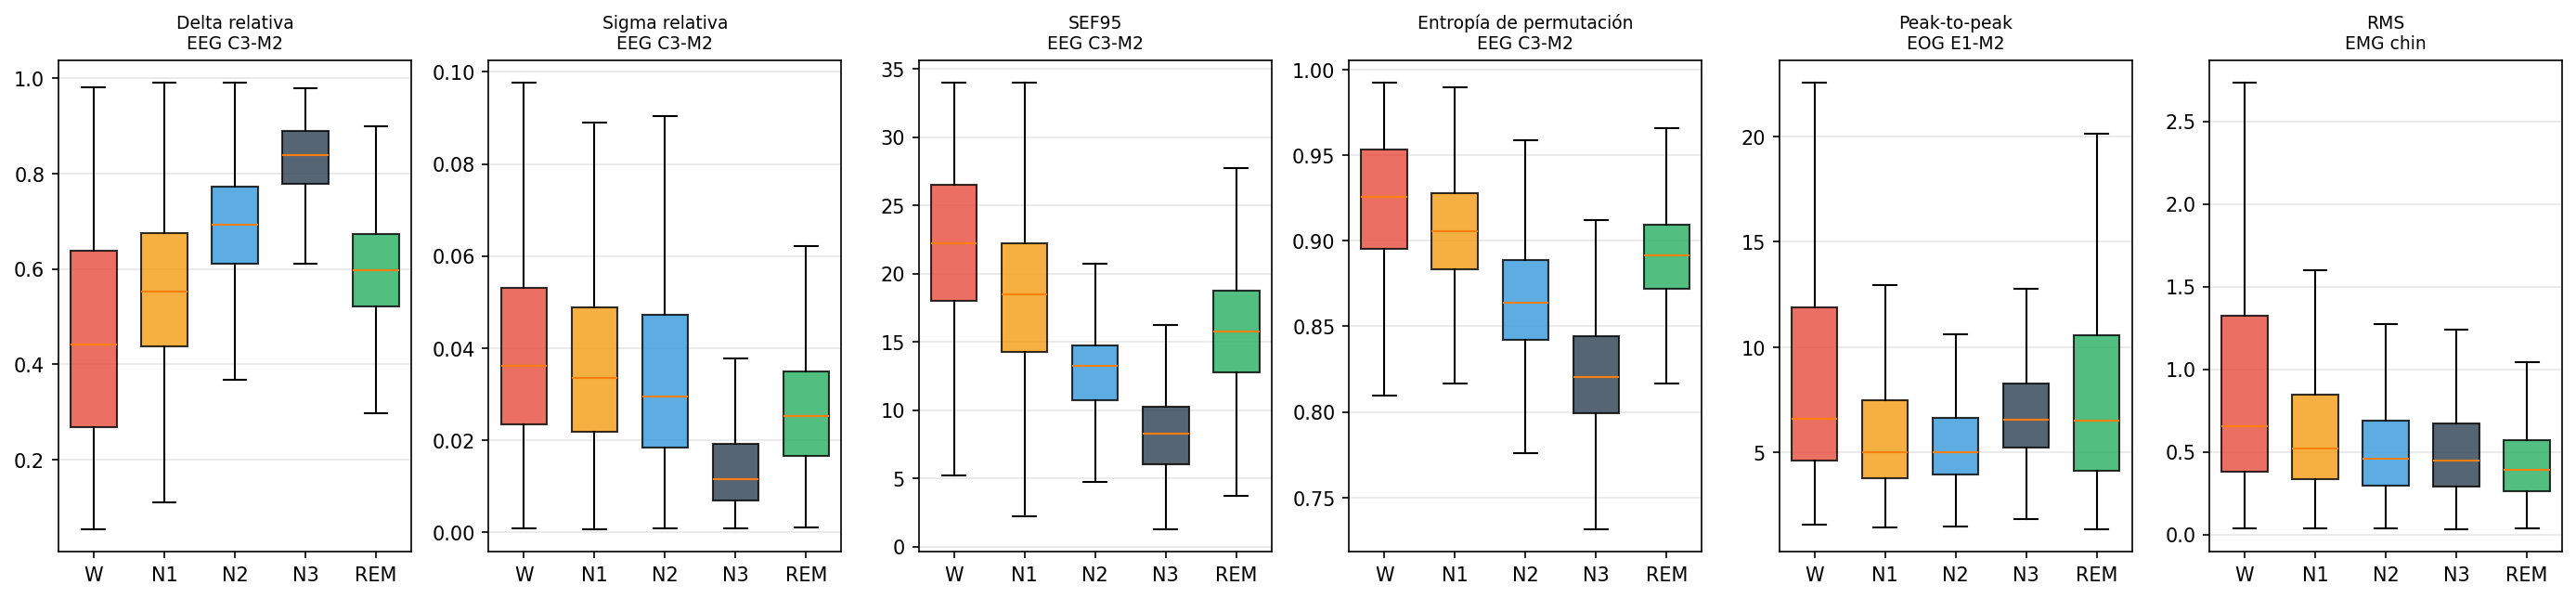

In [25]:
from IPython.display import display, Image

fig.savefig(
    BOXPLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

print("Boxplot guardado:", BOXPLOT_PATH.resolve())

display(
    Image(
        filename=str(BOXPLOT_PATH),
        width=1200,
    )
)

### 6.1 Perfil espectral promedio del EEG principal


In [26]:
HEATMAP_PATH = FIGURES_DIR / "relative_band_power_heatmap.png"

if main_eeg is None:
    print("No se detectó ningún canal EEG.")
else:
    relative_band_cols = [
        f"{main_eeg}__{band}_rel"
        for band in FREQ_BANDS
        if f"{main_eeg}__{band}_rel" in features_df.columns
    ]

    if not relative_band_cols:
        print("No se encontraron columnas de potencia relativa.")
    else:
        profile = (
            features_df
            .groupby("label", observed=True)[relative_band_cols]
            .mean()
        )

        profile.index = [STAGE_MAP[idx] for idx in profile.index]
        profile.columns = [
            col.replace(f"{main_eeg}__", "").replace("_rel", "")
            for col in profile.columns
        ]

        display(profile.round(4))

        fig, ax = plt.subplots(figsize=(7.5, 4.2))
        image = ax.imshow(profile.to_numpy(dtype=np.float32), aspect="auto")

        ax.set_xticks(range(len(profile.columns)), profile.columns)
        ax.set_yticks(range(len(profile.index)), profile.index)
        ax.set_title(f"Potencia relativa promedio por stage — {main_eeg}")
        fig.colorbar(image, ax=ax, label="Potencia relativa")

        for row_idx, row in enumerate(profile.to_numpy()):
            for col_idx, value in enumerate(row):
                ax.text(
                    col_idx,
                    row_idx,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                )

        fig.tight_layout()
        fig.savefig(HEATMAP_PATH, dpi=150, bbox_inches="tight")
        plt.close(fig)

        print("Heatmap guardado:", HEATMAP_PATH.resolve())


,delta,theta,alpha,sigma,beta
W,0.4605,0.1347,0.1875,0.0405,0.1364
N1,0.5624,0.1583,0.1227,0.0376,0.0909
N2,0.6895,0.1361,0.0829,0.0374,0.0362
N3,0.8255,0.0880,0.0475,0.0162,0.0109
REM,0.6028,0.1897,0.0889,0.0276,0.0632


Heatmap guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\figures\relative_band_power_heatmap.png


Heatmap guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\figures\relative_band_power_heatmap.png


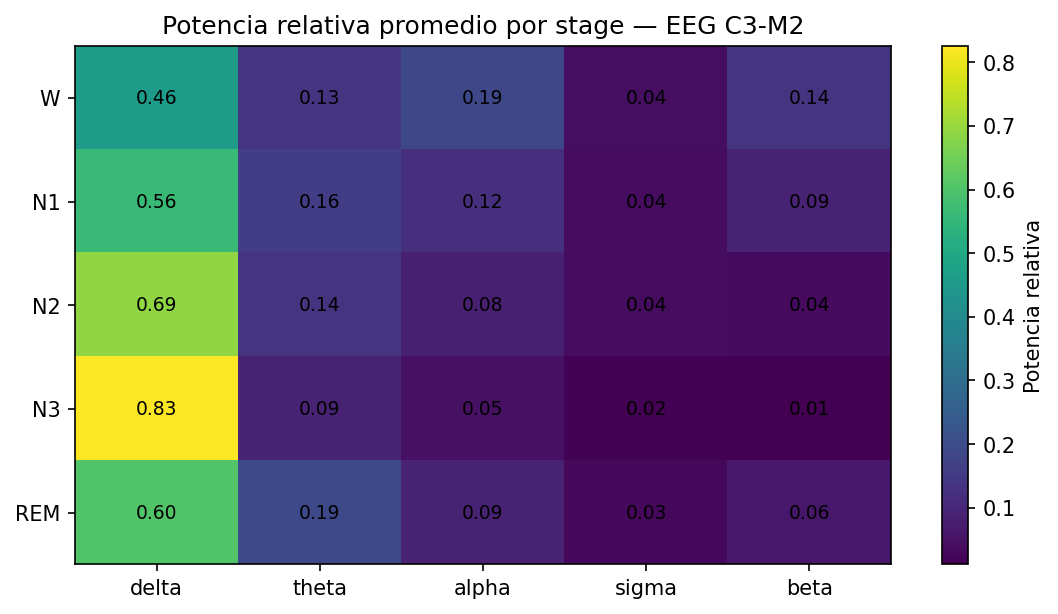

In [27]:
fig.savefig(
    HEATMAP_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

print("Heatmap guardado:", HEATMAP_PATH.resolve())

display(
    Image(
        filename=str(HEATMAP_PATH),
        width=850,
    )
)

### 6.2 Diagnóstico de correlación


In [16]:
correlation_matrix = features_df[FEATURE_COLS].corr().abs()
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .rename("abs_corr")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
    .query("abs_corr >= @HIGH_CORR_THRESHOLD")
    .sort_values("abs_corr", ascending=False)
)

print(
    f"Pares con correlación absoluta ≥ "
    f"{HIGH_CORR_THRESHOLD}: {len(high_corr_pairs)}"
)
display(high_corr_pairs.head(20))


Pares con correlación absoluta ≥ 0.95: 29


,feature_a,feature_b,abs_corr
394,EEG F4-M1__var,EEG F4-M1__hjorth_activity,1.000000
11646,EEG O2-M1__var,EEG O2-M1__hjorth_activity,1.000000
17272,EEG C3-M2__var,EEG C3-M2__hjorth_activity,1.000000
6020,EEG C4-M1__var,EEG C4-M1__hjorth_activity,1.000000
22898,EOG E1-M2__var,EOG E1-M2__hjorth_activity,1.000000
28524,EOG E2-M2__var,EOG E2-M2__hjorth_activity,1.000000
34150,EMG chin__var,EMG chin__hjorth_activity,1.000000
33952,EMG chin__std,EMG chin__rms,1.000000
28326,EOG E2-M2__std,EOG E2-M2__rms,1.000000
22700,EOG E1-M2__std,EOG E1-M2__rms,1.000000


### Extra

,epochs,percentage
label,,
W,19602,15.33
N1,13241,10.35
N2,48237,37.71
N3,26331,20.59
REM,20493,16.02


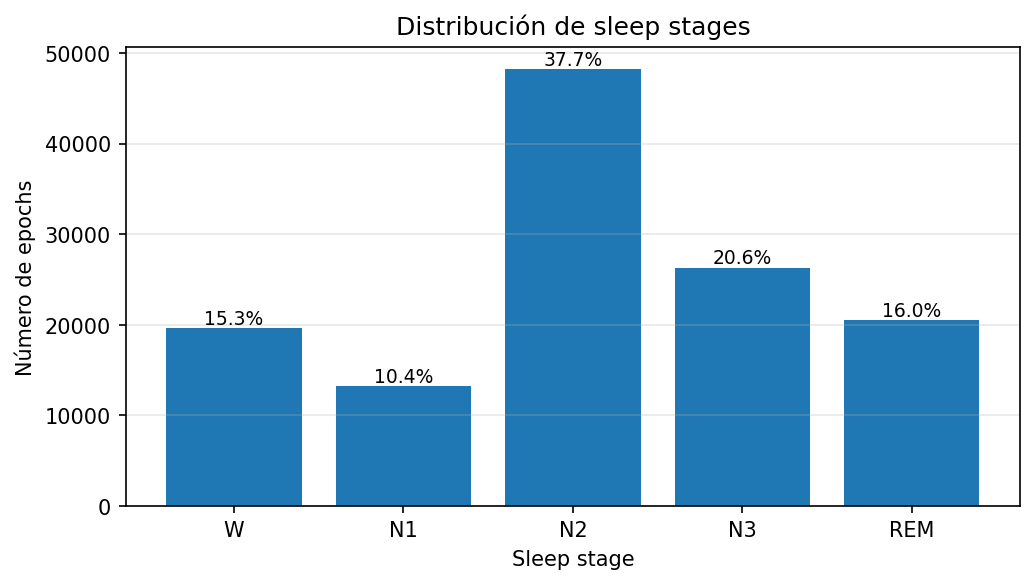

In [28]:
stage_counts = (
    features_df["label"]
    .value_counts()
    .sort_index()
    .rename(index=STAGE_MAP)
)

stage_percentages = 100 * stage_counts / stage_counts.sum()

stage_summary = pd.DataFrame({
    "epochs": stage_counts,
    "percentage": stage_percentages,
})

display(stage_summary.round(2))

CLASS_PLOT_PATH = FIGURES_DIR / "stage_distribution.png"

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    stage_summary.index,
    stage_summary["epochs"],
)

ax.set_title("Distribución de sleep stages")
ax.set_xlabel("Sleep stage")
ax.set_ylabel("Número de epochs")
ax.grid(axis="y", alpha=0.3)

for bar, percentage in zip(bars, stage_summary["percentage"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(CLASS_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(CLASS_PLOT_PATH), width=750))

In [29]:
def univariate_separation_score(data, feature_cols):
    scores = []

    global_means = data[feature_cols].mean()

    for feature in feature_cols:
        grouped = data.groupby("label")[feature]

        class_counts = grouped.count()
        class_means = grouped.mean()
        class_variances = grouped.var().fillna(0)

        between_variance = (
            class_counts
            * (class_means - global_means[feature]) ** 2
        ).sum()

        within_variance = (
            (class_counts - 1).clip(lower=0)
            * class_variances
        ).sum()

        score = between_variance / (within_variance + EPS)

        scores.append({
            "feature": feature,
            "separation_score": score,
        })

    return (
        pd.DataFrame(scores)
        .sort_values("separation_score", ascending=False)
        .reset_index(drop=True)
    )


separation_df = univariate_separation_score(
    features_df,
    FEATURE_COLS,
)

display(separation_df.head(20))

,feature,separation_score
0,EEG C3-M2__zcr,1.033904
1,EEG C4-M1__zcr,0.958734
2,EEG C4-M1__sef95,0.841067
3,EEG C3-M2__sef95,0.786059
4,EEG O2-M1__zcr,0.780690
5,EEG C4-M1__hjorth_mobility,0.778981
6,EEG F4-M1__zcr,0.769724
7,EEG F4-M1__perm_entropy,0.763290
8,EEG C3-M2__perm_entropy,0.763144
9,EEG C3-M2__hjorth_mobility,0.761696


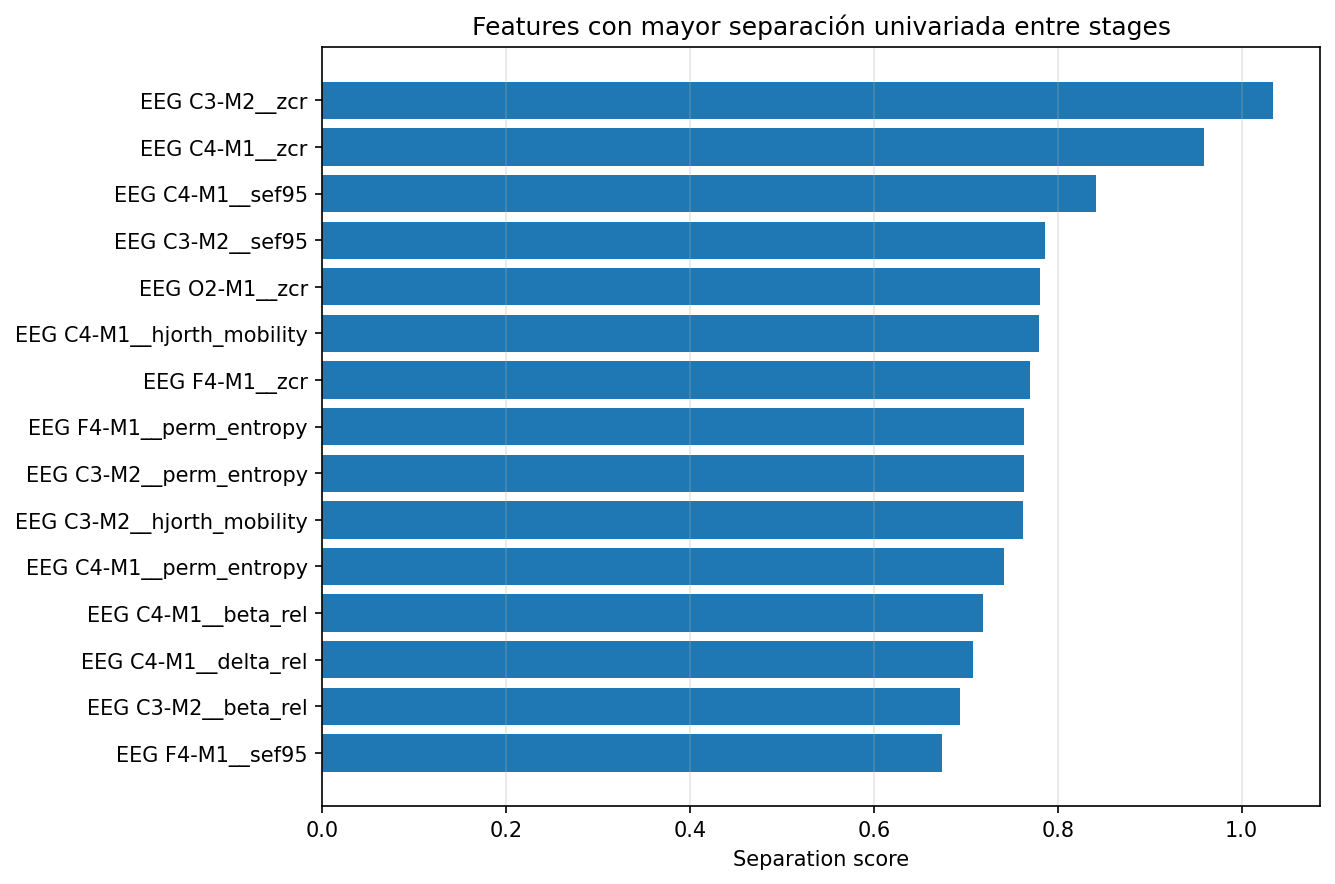

In [30]:
TOP_N = 15

top_features = (
    separation_df
    .head(TOP_N)
    .sort_values("separation_score")
)

SEPARATION_PATH = FIGURES_DIR / "top_univariate_features.png"

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_features["feature"],
    top_features["separation_score"],
)

ax.set_title("Features con mayor separación univariada entre stages")
ax.set_xlabel("Separation score")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(SEPARATION_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(SEPARATION_PATH), width=950))

In [31]:
top_feature_names = separation_df.head(5)["feature"].tolist()

subject_variability = (
    features_df
    .groupby(["subject", "label"], observed=True)[top_feature_names]
    .mean()
    .reset_index()
)

subject_variability.head()

,subject,label,EEG C3-M2__zcr,EEG C4-M1__zcr,EEG C4-M1__sef95,EEG C3-M2__sef95,EEG O2-M1__zcr
0,SN001,0,0.153321,0.156653,18.583969,19.454199,0.142933
1,SN001,1,0.132901,0.138512,16.887754,16.466837,0.122170
2,SN001,2,0.105865,0.110191,12.650118,12.607565,0.108430
3,SN001,3,0.085028,0.090407,10.369565,10.163043,0.097757
4,SN001,4,0.111315,0.114241,13.835145,14.224638,0.104958


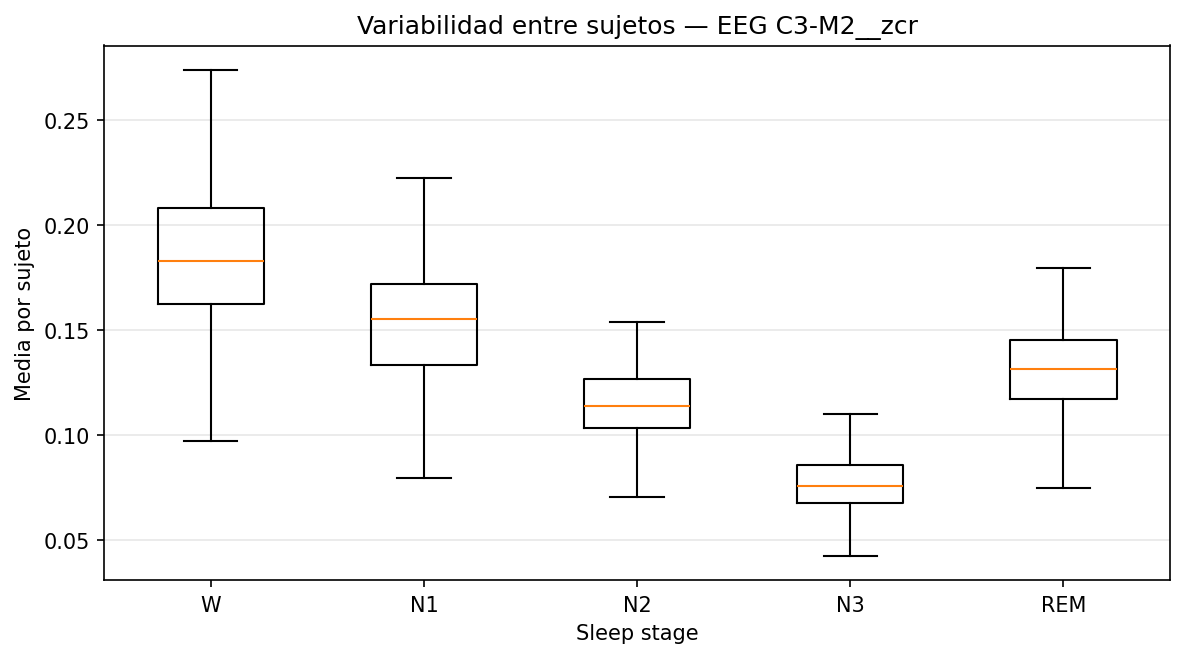

In [32]:
feature_to_plot = top_feature_names[0]

SUBJECT_PLOT_PATH = FIGURES_DIR / "subject_variability.png"

plot_df = (
    subject_variability[
        ["subject", "label", feature_to_plot]
    ]
    .dropna()
)

stage_ids = sorted(plot_df["label"].unique())

fig, ax = plt.subplots(figsize=(8, 4.5))

values_by_stage = [
    plot_df.loc[
        plot_df["label"] == stage_id,
        feature_to_plot,
    ].to_numpy()
    for stage_id in stage_ids
]

ax.boxplot(
    values_by_stage,
    tick_labels=[STAGE_MAP[idx] for idx in stage_ids],
    showfliers=False,
)

ax.set_title(
    f"Variabilidad entre sujetos — {feature_to_plot}"
)
ax.set_xlabel("Sleep stage")
ax.set_ylabel("Media por sujeto")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(SUBJECT_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(SUBJECT_PLOT_PATH), width=850))

---
## 7. Catálogo y guardado final


In [17]:
def feature_family(feature_name):
    suffix = feature_name.split("__", 1)[-1]

    if suffix.startswith("hjorth_"):
        return "hjorth"
    if "entropy" in suffix:
        return "entropy"
    if suffix in {"mean", "std", "var", "rms", "ptp", "skew", "kurt", "zcr"}:
        return "temporal"
    return "spectral"


feature_catalog = pd.DataFrame({
    "feature": FEATURE_COLS,
    "channel": [name.split("__", 1)[0] for name in FEATURE_COLS],
    "family": [feature_family(name) for name in FEATURE_COLS],
    "variance": [float(feature_variance[name]) for name in FEATURE_COLS],
})

feature_catalog["channel_type"] = (
    feature_catalog["channel"].map(infer_channel_type)
)
feature_catalog["is_constant"] = (
    feature_catalog["variance"] <= 1e-12
)

display(
    pd.crosstab(
        feature_catalog["channel_type"],
        feature_catalog["family"],
    )
)


family,entropy,hjorth,spectral,temporal
channel_type,,,,
EEG,8,12,64,32
EMG,2,3,6,8
EOG,4,6,32,16


In [18]:
features_df.to_parquet(
    FINAL_PARQUET,
    index=False,
    compression="snappy",
)

feature_catalog.to_csv(CATALOG_PATH, index=False)

np.savez_compressed(
    FINAL_NPZ,
    X_features=features_df[FEATURE_COLS].to_numpy(dtype=np.float32),
    y=features_df["label"].to_numpy(dtype=np.int8),
    subjects=features_df["subject"].astype(str).to_numpy(),
    epoch_global=features_df["epoch_global"].to_numpy(dtype=np.int32),
    epoch_in_subject=features_df["epoch_in_subject"].to_numpy(dtype=np.int32),
    feature_names=np.asarray(FEATURE_COLS),
)

print("Parquet:", FINAL_PARQUET.resolve())
print("NPZ:    ", FINAL_NPZ.resolve())
print("Catálogo:", CATALOG_PATH.resolve())


Parquet: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed\features_full.parquet
NPZ:     C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed\features_full.npz
Catálogo: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed\feature_catalog.csv


---
## 8. Checklist final


In [19]:
checks = {
    "Dataset alineado": len(features_df) == len(y) == len(subjects),
    "Sin NaN ni infinitos": np.isfinite(
        features_df[FEATURE_COLS].to_numpy()
    ).all(),
    "Metadata de sujeto": "subject" in features_df.columns,
    "Orden temporal": "epoch_in_subject" in features_df.columns,
    "Parquet guardado": FINAL_PARQUET.exists(),
    "NPZ guardado": FINAL_NPZ.exists(),
    "Catálogo guardado": CATALOG_PATH.exists(),
}

print("=" * 68)
print("CHECKLIST — FEATURE ENGINEERING")
print("=" * 68)

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print("\nResumen:")
print(f"  epochs:              {len(features_df)}")
print(f"  sujetos:             {features_df['subject'].nunique()}")
print(f"  features:            {len(FEATURE_COLS)}")
print(f"  features constantes: {len(constant_features)}")

print("\nPróximo paso:")
print("  Entrenar el baseline con validación agrupada por sujeto.")


CHECKLIST — FEATURE ENGINEERING
✅  Dataset alineado
✅  Sin NaN ni infinitos
✅  Metadata de sujeto
✅  Orden temporal
✅  Parquet guardado
✅  NPZ guardado
✅  Catálogo guardado

Resumen:
  epochs:              127904
  sujetos:             151
  features:            193
  features constantes: 0

Próximo paso:
  Entrenar el baseline con validación agrupada por sujeto.
